# 01 · Data analysis: AI-assisted vs conventional study (crossover, paired design)

**Project:** *Effectiveness of Generative AI Tools for University Students' Understanding of Academic Material* (Narxoz University).
**Task:** TASK 3 — research results, data analysis and scientific visualization.

> ⚠️ **Data status.** `data/raw/test_run.jsonl` currently holds **synthetic (simulated) records** produced by
> `src/generate_sample_data.py` (seed 42) to verify the whole pipeline. All numbers below demonstrate the *method*;
> they are **not** empirical findings. Replacing the file with real pseudonymised records (same schema) and re-running
> *Restart & Run All* regenerates every table and figure.

**How the TASK 3 benchmarking vocabulary maps onto this study**

| TASK 3 template term | Meaning in this study |
|---|---|
| *Cold-start / warm-up run* | Practice (familiarisation) session with each tool (`phase = "warmup"`) — discarded |
| *Evaluation run* | Real session on a matched module (`phase = "evaluation"`) |
| *Baseline vs Proposed method* | Conventional study (lecture notes / textbook) vs AI-assisted study |
| *Latency / throughput* | Test score (points), normalized gain (unitless), efficiency (points/min), study time (min) |
| *Error rate (guardrail metric)* | Share of records violating validation rules (score range, time ≤ 30 min, 7-day delay, missing fields) |

**Notebook structure:** 1) setup & seed → 2) ingestion & warm-up filtering → 3) guardrails → 4) statistical aggregation →
5) paired effects → 6) order-effect check → 7) visualization & export → 8) reproducibility checks & conclusions.

## 1 · Setup and reproducibility
A single seed (`42`) drives NumPy and every bootstrap / permutation procedure in `src/process_data.py`.

In [1]:
import os, sys, platform
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                      # all config paths are relative to the repo root
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scipy, matplotlib, seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from src import process_data as pdm
from src import visualize as viz

SEED = 42
np.random.seed(SEED)                # fixed seed (numpy global state)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")
print("Repo root:", ROOT)
print("Seed:", SEED)

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scipy 1.17.1 | matplotlib 3.10.8 | seaborn 0.13.2
Repo root: /home/claude/repo
Seed: 42


## 2 · Data ingestion and warm-up filtering
Raw records are stored as JSON-lines (one session per line).

In [2]:
cfg = pdm.load_config("configs/task3_config.json")
raw = pdm.load_jsonl(cfg["raw_path"])
print("Raw records:", raw.shape)
display(raw.head(6))
print("\nRecords per phase x condition:")
display(pd.crosstab(raw["phase"], raw["condition"], margins=True))

Raw records: (80, 12)


,record_id,participant_id,phase,condition,module,period,sequence,pre_score,post_score,delayed_score,study_time_min,delayed_interval_days
0,1,P01,warmup,AI,P,0,AI-A>Conv-B,2.5,5.5,NaN,37.8,NaN
1,2,P01,warmup,Conventional,P,0,AI-A>Conv-B,1.5,2.5,NaN,34.5,NaN
2,3,P01,evaluation,AI,A,1,AI-A>Conv-B,4.0,8.0,7.0,25.9,7.0
3,4,P01,evaluation,Conventional,B,2,AI-A>Conv-B,5.0,7.5,5.5,28.0,7.0
4,5,P02,warmup,AI,P,0,AI-B>Conv-A,4.0,5.0,NaN,37.5,NaN
5,6,P02,warmup,Conventional,P,0,AI-B>Conv-A,3.5,5.0,NaN,31.3,NaN



Records per phase x condition:


condition,AI,Conventional,All
phase,,,
evaluation,20,20,40
warmup,20,20,40
All,40,40,80


**Why filter warm-up?** In the first (practice) session students are still learning the interface and the prompt guide:
gains are lower and the time on task is longer and erratic (the "cold" spike). Keeping those runs would bias both
conditions and break the 30-minute protocol guardrail. They are therefore stored but excluded **before** any statistic.

In [3]:
warm, evaluation = pdm.split_warmup(raw)
cols = ["study_time_min", "pre_score", "post_score"]
cmp_ = pd.concat({"warm-up (discarded)": warm[cols].describe().T[["count", "mean", "std", "min", "max"]],
                  "evaluation (kept)": evaluation[cols].describe().T[["count", "mean", "std", "min", "max"]]})
display(cmp_.round(2))
share = (warm["study_time_min"] > cfg["max_study_minutes"]).mean()
print(f"Warm-up records breaking the {cfg['max_study_minutes']}-min limit: {share:.0%}  "
      f"-> would have violated the guardrail had they not been removed.")
print(f"Discarded warm-up records: {len(warm)} | evaluation records kept for validation: {len(evaluation)}")

count   mean   std   min   max
warm-up (discarded) study_time_min   40.0  34.48  3.50  28.1  42.4
                    pre_score        40.0   3.84  1.27   1.5   7.0
                    post_score       40.0   5.54  1.32   2.5   8.5
evaluation (kept)   study_time_min   40.0  25.38  1.97  21.2  28.6
                    pre_score        40.0   3.74  1.33   1.0   6.0
                    post_score       40.0   7.31  1.21   4.5  11.0

Warm-up records breaking the 30-min limit: 90%  -> would have violated the guardrail had they not been removed.
Discarded warm-up records: 40 | evaluation records kept for validation: 40


## 3 · Guardrail metrics (data quality)
Rules (from the Methodology Passport Card): no missing required fields; scores within [0, 10]; study time in (0, 30] min;
delayed test exactly 7 days after the session. Invalid rows are **not silently deleted** — they are reported, counted as the
**error rate** (guardrail metric) and saved to `data/processed/excluded_records.csv`.

In [4]:
valid, invalid, guard = pdm.validate_records(evaluation, cfg)
print("Guardrail report:")
for k, v in guard.items():
    print(f"  {k}: {v}")
print("\nExcluded record(s):")
display(invalid[["record_id", "participant_id", "condition", "pre_score", "post_score", "error_reason"]])

Guardrail report:
  n_records_checked: 40
  n_invalid: 1
  error_rate: 0.025
  error_rate_by_condition: {'AI': 0.05, 'Conventional': 0.0}
  threshold: 0.05
  guardrail_ok: True

Excluded record(s):


,record_id,participant_id,condition,pre_score,post_score,error_reason
32,67,P17,AI,6.0,11.0,post_score_out_of_range


In [5]:
derived, ceiling = pdm.add_derived(valid, cfg)     # normalized gain, efficiency; ceiling rule (pre == 10)
data = pdm.complete_pairs(derived)                 # paired design: both conditions needed per student
print(f"Ceiling-pretest exclusions: {len(ceiling)}")
print(f"Students with a complete valid pair: {data['participant_id'].nunique()} "
      f"(records: {len(data)}; pair dropped because its partner record was invalid)")
display(data[["participant_id", "condition", "module", "period", "pre_score", "post_score",
              "delayed_score", "study_time_min", "norm_gain", "efficiency"]].head(8).round(3))

Ceiling-pretest exclusions: 0
Students with a complete valid pair: 19 (records: 38; pair dropped because its partner record was invalid)


,participant_id,condition,module,period,pre_score,post_score,delayed_score,study_time_min,norm_gain,efficiency
0,P01,AI,A,1,4.0,8.0,7.0,25.9,0.667,0.154
1,P01,Conventional,B,2,5.0,7.5,5.5,28.0,0.500,0.089
2,P02,AI,B,1,5.0,7.5,6.5,23.2,0.500,0.108
3,P02,Conventional,A,2,4.0,7.0,5.5,27.9,0.500,0.108
4,P03,Conventional,A,1,4.0,7.5,6.0,28.6,0.583,0.122
5,P03,AI,B,2,5.5,8.5,7.0,24.3,0.667,0.123
6,P04,Conventional,B,1,2.5,6.0,5.0,25.6,0.467,0.137
7,P04,AI,A,2,4.0,9.0,8.0,26.1,0.833,0.192


## 4 · Statistical aggregation
For every metric and condition: **median, p25–p75, p95, p99, mean ± SD** and **percentile-bootstrap 95% CI**
(10 000 resamples, seed 42) for the mean and the median.
*Note:* with n = 19 the p95/p99 are interpolated and sit close to the sample maximum — they describe the tail of this
small sample and are reported as required, but should not be over-interpreted.

In [6]:
summary = pdm.summarize_by_condition(data, cfg)
display(summary[["metric", "condition", "n", "median", "p25", "p75", "p95", "p99",
                 "median_ci_low", "median_ci_high"]])

,metric,condition,n,median,p25,p75,p95,p99,median_ci_low,median_ci_high
0,norm_gain,AI,19,0.6250,0.5774,0.6667,0.8357,0.8529,0.5833,0.6667
1,norm_gain,Conventional,19,0.5000,0.4333,0.5774,0.6364,0.6364,0.4667,0.5714
2,delayed_score,AI,19,7.0000,5.7500,7.5000,8.0000,8.0000,6.0000,7.5000
3,delayed_score,Conventional,19,5.5000,5.0000,6.2500,7.5000,7.5000,5.0000,6.0000
4,efficiency,AI,19,0.1653,0.1314,0.2019,0.2426,0.2522,0.1394,0.1916
5,efficiency,Conventional,19,0.1220,0.0942,0.1332,0.1609,0.1666,0.0969,0.1296
6,study_time_min,AI,19,24.2000,23.1000,25.4500,26.3600,27.5120,23.1000,25.1000
7,study_time_min,Conventional,19,27.0000,25.7000,27.6500,28.1500,28.5100,25.8000,27.4000


In [7]:
pretty = summary.copy()
pretty["Mean ± SD"] = pretty.apply(pdm.fmt_mean_sd, axis=1)
pretty["Median (p25–p75)"] = pretty.apply(pdm.fmt_median_iqr, axis=1)
pretty["Mean 95% CI"] = pretty.apply(lambda r: f"[{r['mean_ci_low']:.2f}, {r['mean_ci_high']:.2f}]", axis=1)
display(pretty[["label", "condition", "Mean ± SD", "Median (p25–p75)", "Mean 95% CI"]].set_index(["label", "condition"]))

Mean ± SD     Median (p25–p75)     Mean 95% CI
label                                condition                                                      
Normalized immediate gain (unitless) AI             0.63 ± 0.10     0.62 (0.58–0.67)    [0.59, 0.68]
                                     Conventional   0.48 ± 0.12     0.50 (0.43–0.58)    [0.43, 0.53]
Day-7 delayed score (points, 0-10)   AI             6.61 ± 1.06     7.00 (5.75–7.50)    [6.13, 7.05]
                                     Conventional   5.63 ± 1.13     5.50 (5.00–6.25)    [5.13, 6.13]
Learning efficiency (points/min)     AI             0.17 ± 0.05     0.17 (0.13–0.20)    [0.15, 0.19]
                                     Conventional   0.11 ± 0.03     0.12 (0.09–0.13)    [0.10, 0.13]
Study time (min)                     AI            24.16 ± 1.74  24.20 (23.10–25.45)  [23.42, 24.93]
                                     Conventional  26.65 ± 1.33  27.00 (25.70–27.65)  [26.04, 27.21]

## 5 · Paired effects (AI − Conventional)
Unit of analysis = student (within-student difference). Reported: mean difference with **bootstrap 95% CI**, Cohen's $d_z$, and
three one-sided tests (paired t-test, sign-flip permutation, Wilcoxon). RQ1 is the primary analysis; RQ2/RQ3 are secondary
(not corrected for multiplicity); study time is descriptive (two-sided).

In [8]:
effects = pdm.paired_effects(data, cfg)
display(effects[["metric", "n_pairs", "mean_diff", "diff_ci_low", "diff_ci_high", "cohens_dz",
                 "p_ttest", "p_permutation", "p_wilcoxon"]])

,metric,n_pairs,mean_diff,diff_ci_low,diff_ci_high,cohens_dz,p_ttest,p_permutation,p_wilcoxon
0,norm_gain,19,0.1504,0.0832,0.2191,0.9661,0.0003,0.0001,0.0008
1,delayed_score,19,0.9737,0.3947,1.5526,0.7513,0.0021,0.0032,0.0048
2,efficiency,19,0.0537,0.0316,0.0749,1.0812,0.0001,0.0001,0.0001
3,study_time_min,19,-2.4895,-3.4895,-1.4211,-1.0408,0.0003,0.0005,0.0019


In [9]:
rq = {"norm_gain": "RQ1 (primary)", "delayed_score": "RQ2 (retention)", "efficiency": "RQ3 (efficiency)",
      "study_time_min": "Study time (descriptive)"}
for _, e in effects.iterrows():
    excl0 = (e.diff_ci_low > 0) or (e.diff_ci_high < 0)
    print(f"{rq[e.metric]:<26} Δ = {e.mean_diff:+.3f}  95% CI [{e.diff_ci_low:+.3f}, {e.diff_ci_high:+.3f}]  "
          f"d_z = {e.cohens_dz:.2f}  p(perm) = {e.p_permutation:.4f}  -> CI {'excludes' if excl0 else 'includes'} 0")
print("\nREMINDER: data are synthetic; this output verifies the pipeline, it is NOT evidence about real students.")

RQ1 (primary)              Δ = +0.150  95% CI [+0.083, +0.219]  d_z = 0.97  p(perm) = 0.0001  -> CI excludes 0
RQ2 (retention)            Δ = +0.974  95% CI [+0.395, +1.553]  d_z = 0.75  p(perm) = 0.0032  -> CI excludes 0
RQ3 (efficiency)           Δ = +0.054  95% CI [+0.032, +0.075]  d_z = 1.08  p(perm) = 0.0001  -> CI excludes 0
Study time (descriptive)   Δ = -2.490  95% CI [-3.490, -1.421]  d_z = -1.04  p(perm) = 0.0005  -> CI excludes 0

REMINDER: data are synthetic; this output verifies the pipeline, it is NOT evidence about real students.


## 6 · Design-factor check (order / carry-over)
In a crossover study the paired difference should not depend on which condition came first. Quick exploratory check:
compare the individual normalized-gain differences between the *AI-first* and *Conventional-first* groups (Welch t-test).

In [10]:
w = pdm.paired_wide(data, "norm_gain")
first = data.drop_duplicates("participant_id").set_index("participant_id")["sequence"].str.startswith("AI")
d = (w["AI"] - w["Conventional"])
g_ai_first, g_conv_first = d[first.reindex(d.index)], d[~first.reindex(d.index)]
t_o = stats.ttest_ind(g_ai_first, g_conv_first, equal_var=False)
print(f"AI-first (n={len(g_ai_first)}): mean Δ = {g_ai_first.mean():.3f} | "
      f"Conventional-first (n={len(g_conv_first)}): mean Δ = {g_conv_first.mean():.3f}")
print(f"Welch t = {t_o.statistic:.2f}, p = {t_o.pvalue:.3f}  "
      f"-> {'no clear' if t_o.pvalue > 0.05 else 'POSSIBLE'} order effect in this sample (low power, n≈10 per group)")

AI-first (n=9): mean Δ = 0.073 | Conventional-first (n=10): mean Δ = 0.220
Welch t = -2.30, p = 0.035  -> POSSIBLE order effect in this sample (low power, n≈10 per group)


## 7 · Visualization and export
All figures follow the three scientific-visualization rules: **(1)** axes with physical units, **(2)** 95% CI shown
(shaded band + error bars), **(3)** colour-blind-safe palette (`sns.color_palette("colorblind")`) plus different line styles,
markers and hatches for black-and-white printing. Scores lie within 0–10 (less than one order of magnitude), so a linear axis
is appropriate (a log axis is reserved for metrics spanning orders of magnitude). Every figure is saved as vector PDF **and**
PNG at 300 DPI in `reports/figures/`.

,condition,stage,mean,ci_low,ci_high,n
0,AI,Pretest\n(day 0),3.632,3.000,4.263,19
1,AI,Posttest\n(day 0),7.658,7.263,8.026,19
2,AI,Delayed test\n(day 7),6.605,6.132,7.053,19
3,Conventional,Pretest\n(day 0),3.711,3.184,4.263,19
4,Conventional,Posttest\n(day 0),6.737,6.263,7.184,19
5,Conventional,Delayed test\n(day 7),5.632,5.132,6.132,19


reports/figures/fig1_latency_vs_load.pdf
reports/figures/fig1_latency_vs_load.png


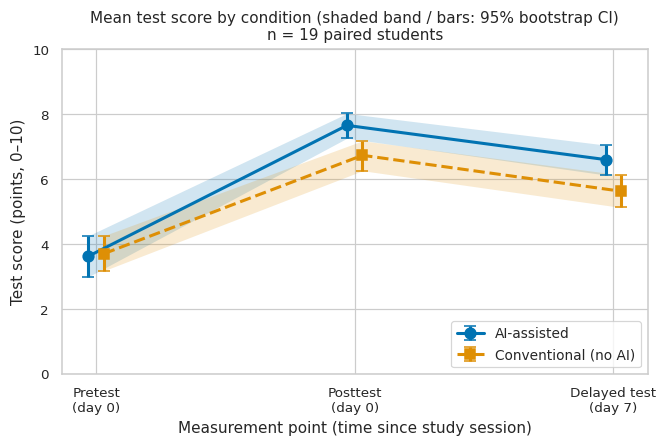

In [11]:
traj = pdm.score_trajectory(data, cfg)
display(traj.round(3))
fig1 = viz.fig1_latency_vs_load(traj, n_pairs=data["participant_id"].nunique())
print(*viz.save_figure(fig1, "fig1_latency_vs_load"), sep="\n")
plt.show()

reports/figures/fig2_distribution_boxplot.pdf
reports/figures/fig2_distribution_boxplot.png


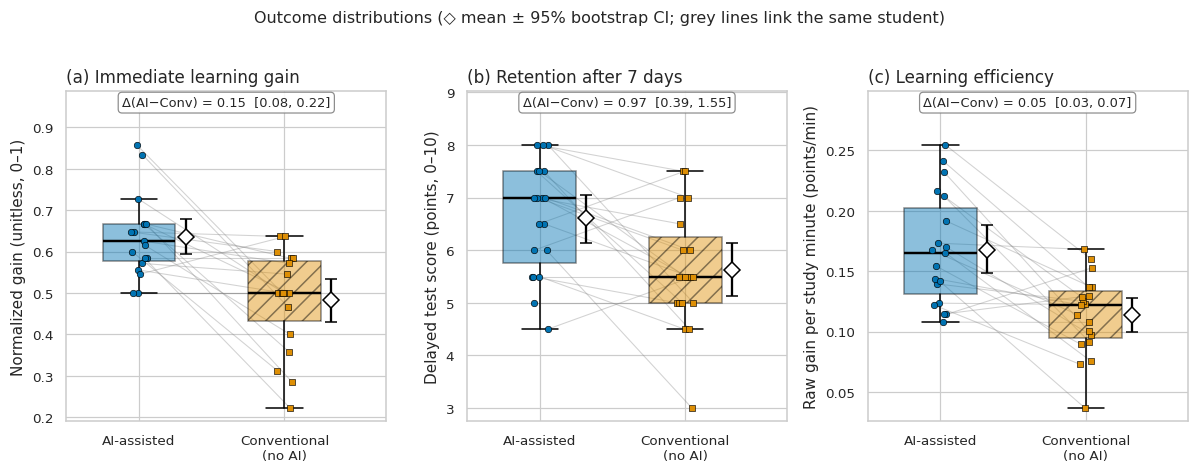

In [12]:
fig2 = viz.fig2_distribution_boxplot(data, effects, cfg)
print(*viz.save_figure(fig2, "fig2_distribution_boxplot"), sep="\n")
plt.show()

In [13]:
from PIL import Image
for name in ("fig1_latency_vs_load", "fig2_distribution_boxplot"):
    pdf, png = Path(f"reports/figures/{name}.pdf"), Path(f"reports/figures/{name}.png")
    dpi = Image.open(png).info.get("dpi", (0, 0))[0]
    print(f"{name}: pdf={pdf.exists()} ({pdf.stat().st_size/1024:.0f} KB) | png={png.exists()} | PNG dpi={dpi:.0f} "
          f"{'OK (>=300)' if round(dpi) >= 300 else 'TOO LOW'}")

fig1_latency_vs_load: pdf=True (14 KB) | png=True | PNG dpi=300 OK (>=300)
fig2_distribution_boxplot: pdf=True (22 KB) | png=True | PNG dpi=300 OK (>=300)


## 8 · Export of processed data and reproducibility checks

In [14]:
for key in ("summary_path", "effects_path", "guardrail_path", "excluded_path"):
    Path(cfg[key]).parent.mkdir(parents=True, exist_ok=True)
summary.to_csv(cfg["summary_path"], index=False)
effects.to_csv(cfg["effects_path"], index=False)
invalid.to_csv(cfg["excluded_path"], index=False)
guard.update({"n_raw_records": int(len(raw)), "n_warmup_discarded": int(len(warm)),
              "n_ceiling_excluded": int(len(ceiling)), "n_pairs_analysed": int(data["participant_id"].nunique())})
import json; Path(cfg["guardrail_path"]).write_text(json.dumps(guard, indent=2), encoding="utf-8")
print("Written:", cfg["summary_path"], cfg["effects_path"], cfg["guardrail_path"], cfg["excluded_path"], sep="\n  ")
display(pd.read_csv(cfg["summary_path"]).head(4))

Written:
  data/processed/metrics_summary.csv
  data/processed/paired_effects.csv
  data/processed/guardrail_report.json
  data/processed/excluded_records.csv


,metric,label,condition,n,mean,sd,median,p25,p75,p95,p99,mean_ci_low,mean_ci_high,median_ci_low,median_ci_high
0,norm_gain,Normalized immediate gain (unitless),AI,19,0.6346,0.0953,0.625,0.5774,0.6667,0.8357,0.8529,0.5943,0.6775,0.5833,0.6667
1,norm_gain,Normalized immediate gain (unitless),Conventional,19,0.4842,0.1186,0.500,0.4333,0.5774,0.6364,0.6364,0.4309,0.5330,0.4667,0.5714
2,delayed_score,"Day-7 delayed score (points, 0-10)",AI,19,6.6053,1.0617,7.000,5.7500,7.5000,8.0000,8.0000,6.1316,7.0526,6.0000,7.5000
3,delayed_score,"Day-7 delayed score (points, 0-10)",Conventional,19,5.6316,1.1284,5.500,5.0000,6.2500,7.5000,7.5000,5.1316,6.1316,5.0000,6.0000


In [15]:
# Reproducibility check: the standalone pipeline (src/process_data.py) must give identical numbers
res = pdm.run_pipeline(cfg, write=False)
pd.testing.assert_frame_equal(res["summary"], summary)
pd.testing.assert_frame_equal(res["effects"], effects)
print("OK: notebook results == src/process_data.py pipeline results (seed =", SEED, ")")

OK: notebook results == src/process_data.py pipeline results (seed = 42 )


## 9 · Conclusions and limitations (read before citing any number)
* **Pipeline:** warm-up runs are removed, guardrails are tracked as an error rate, medians / p95 / p99 / mean ± SD and bootstrap 95% CI are computed,
  and the paired AI − Conventional effect is estimated for RQ1–RQ3 with an uncertainty interval — exactly the plan of the Methodology Passport Card.
* **Data:** the current numbers come from **simulated** records (n = 20 planned students, 19 complete pairs after one guardrail exclusion). They show that the
  method works; with real data the same notebook yields the real answer.
* **Limitations:** small n; p95/p99 are tail estimates of a tiny sample; secondary outcomes are not multiplicity-adjusted; the crossover design assumes no
  carry-over (checked only exploratorily in §6 — for the current synthetic sample it flags a possible order effect, uncorrected p ≈ 0.035, n ≈ 10 per group; *update this sentence after re-running with real data* and, with real data, model `sequence`/`period` explicitly); a single university and two modules limit external validity; association within this design supports a causal
  reading only if randomisation and counterbalancing were actually followed.